# Solar Aruba: análisis exploratorio de los datos
**Grupo 4 · Curso 2026/27**

En este cuaderno revisamos los datos de `aruba_cruzado_5min (1).csv` para conocer su calidad,
ver cómo cambia la radiación y estudiar qué variables pueden ser útiles para el proyecto.
Seguimos el planteamiento de *Solar Aruba Anteproyecto (1).pdf*, especialmente la preparación
de datos, la integración por estación y fecha y los retardos de 5, 10, 15 y 20 minutos.

El anteproyecto propone predecir producción o potencia solar a 15 minutos. **Este CSV no tiene
generación eléctrica medida**, potencia instalada ni datos de limpieza de paneles.
Por eso usamos `shortwave_radiation_instant` como **variable de interés de este EDA**.
Después exploramos su valor a 15 minutos como objetivo provisional. La radiación representa
el recurso solar disponible y no equivale a la energía que produce una instalación.

Nos planteamos estas preguntas:
1. ¿Hay datos ausentes, duplicados o valores que debamos revisar?
2. ¿Qué patrones aparecen por hora, mes y estación?
3. ¿Cómo se relaciona la radiación con las variables meteorológicas y las otras radiaciones?
4. ¿Qué debemos tener en cuenta antes de preparar una predicción a 15 minutos?

**Para ejecutarlo:** guardar el notebook junto al CSV y ejecutar las celdas de arriba abajo.
Necesitamos Python 3, pandas, matplotlib y seaborn. Los gráficos se generan al ejecutar sus celdas.


## 1. Carga y primera revisión
Empezamos por cargar el archivo y revisar las columnas. Conservamos una copia de los datos
originales para poder comparar después de la preparación.


In [2]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
DATASET_PATH = DATA_DIR / "aruba_cruzado_5min_con_energia.csv"

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import timezone, timedelta
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 35)

datos_originales = pd.read_csv(DATASET_PATH, encoding="utf-8-sig")
datos = datos_originales.copy()
objetivo = "shortwave_radiation_instant"

print("Filas:", datos.shape[0])
print("Columnas:", datos.shape[1])
display(datos.head())


Filas: 219984
Columnas: 36


,station_id,station_name,station_code,latitude,longitude,elevation_m,district,is_active,timestamp,reading_id,reading_available,temperature_c,humidity_pct,wind_speed_kmh,wind_direction_deg,pressure_hpa,precipitation_mm,...,shortwave_radiation_instant,direct_normal_irradiance_instant,diffuse_radiation_instant,direct_radiation_instant,cloud_cover,is_day,sunshine_duration_source_s,radiation_source_timestamp,radiation_quality,wind_speed_ms,radiacion_aproximada_wm2,temperatura_celda_estimada_c,potencia_limpia_mw,energia_limpia_kwh,soiling_factor_supuesto,potencia_estimada_mw,energia_estimada_kwh
0,963fdb57-b257-472d-b56e-892b265c2524,San Nicolaas,WS-SNC-09,12.4364,-69.9090,8,San Nicolaas,True,2025-09-01T00:00:00Z,ce7a3b1c-2f9b-4c5c-8890-93c50dbadbf1,True,31.6,68.4,22.2,41.8,1013.3,0.0,...,0.0,0.0,0.0,0.0,99.0,0.0,0.0,2025-09-01T00:00:00Z,repetido_desde_hora,6.166667,0.0,31.6,0.0,0.0,1.0,0.0,0.0
1,de2ee07b-de63-49db-a669-64177a688bbf,Queen Beatrix Airport,WS-APT-02,12.5042,-70.0031,18,Oranjestad,True,2025-09-01T00:00:00Z,ab911552-90f1-432d-993b-85aa0d01bb60,True,31.4,68.1,22.7,44.4,1013.3,0.0,...,0.0,0.0,0.0,0.0,100.0,0.0,0.0,2025-09-01T00:00:00Z,repetido_desde_hora,6.305556,0.0,31.4,0.0,0.0,1.0,0.0,0.0
2,963fdb57-b257-472d-b56e-892b265c2524,San Nicolaas,WS-SNC-09,12.4364,-69.9090,8,San Nicolaas,True,2025-09-01T00:05:00Z,26a81205-9843-428f-950b-52a064f2a97b,True,31.6,68.5,22.3,41.3,1013.3,0.0,...,0.0,0.0,0.0,0.0,99.0,0.0,0.0,2025-09-01T00:00:00Z,repetido_desde_hora,6.194444,0.0,31.6,0.0,0.0,1.0,0.0,0.0
3,de2ee07b-de63-49db-a669-64177a688bbf,Queen Beatrix Airport,WS-APT-02,12.5042,-70.0031,18,Oranjestad,True,2025-09-01T00:05:00Z,f89fd989-b3da-4b5b-9956-04bb3dddff2d,True,31.6,67.8,22.6,45.1,1013.2,0.0,...,0.0,0.0,0.0,0.0,100.0,0.0,0.0,2025-09-01T00:00:00Z,repetido_desde_hora,6.277778,0.0,31.6,0.0,0.0,1.0,0.0,0.0
4,963fdb57-b257-472d-b56e-892b265c2524,San Nicolaas,WS-SNC-09,12.4364,-69.9090,8,San Nicolaas,True,2025-09-01T00:10:00Z,80d27ac5-4592-4871-8ec2-d92779dc8e70,True,31.6,68.7,22.6,41.4,1013.3,0.0,...,0.0,0.0,0.0,0.0,99.0,0.0,0.0,2025-09-01T00:00:00Z,repetido_desde_hora,6.277778,0.0,31.6,0.0,0.0,1.0,0.0,0.0


In [3]:
datos.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 219984 entries, 0 to 219983
Data columns (total 36 columns):
 #   Column                            Non-Null Count   Dtype  
---  ------                            --------------   -----  
 0   station_id                        219984 non-null  object 
 1   station_name                      219984 non-null  object 
 2   station_code                      219984 non-null  object 
 3   latitude                          219984 non-null  float64
 4   longitude                         219984 non-null  float64
 5   elevation_m                       219984 non-null  int64  
 6   district                          219984 non-null  object 
 7   is_active                         219984 non-null  bool   
 8   timestamp                         219984 non-null  object 
 9   reading_id                        211344 non-null  object 
 10  reading_available                 219984 non-null  bool   
 11  temperature_c                     211344 non-null  f

### Qué representa cada grupo de variables
Cada fila corresponde a una estación y un instante de cinco minutos. El archivo mezcla
lecturas meteorológicas con datos solares que tienen su propia fecha de origen.

| Grupo | Columnas | Uso en el análisis |
|---|---|---|
| Estación | `station_id`, `station_name`, `station_code`, `district` | Identificar y comparar estaciones |
| Ubicación | `latitude`, `longitude`, `elevation_m` | Situar las estaciones; no representan instalaciones solares |
| Control | `is_active`, `reading_id`, `reading_available` | Revisar actividad y disponibilidad de lecturas |
| Tiempo | `timestamp` | Ordenar las observaciones y construir retardos |
| Meteorología | `temperature_c`, `humidity_pct`, `wind_speed_kmh`, `wind_direction_deg`, `pressure_hpa`, `precipitation_mm`, `visibility_km`, `uv_index` | Estudiar relaciones con la radiación |
| Radiación | `shortwave_radiation_instant`, `direct_normal_irradiance_instant`, `diffuse_radiation_instant`, `direct_radiation_instant` | Radiación total y componentes |
| Condiciones solares | `cloud_cover`, `is_day`, `sunshine_duration_source_s` | Nubosidad, día/noche y duración de insolación en el periodo de origen |
| Origen del cruce | `radiation_source_timestamp`, `radiation_quality` | Comprobar la resolución y procedencia temporal |

Las unidades meteorológicas aparecen en los nombres: °C, %, km/h, grados, hPa, mm y km.
Para las radiaciones utilizamos provisionalmente W/m² y para `cloud_cover`, porcentaje.
El CSV no incluye un diccionario de unidades: habrá que confirmarlas en la fuente antes de
convertir radiación en energía. Tampoco sumamos `sunshine_duration_source_s` en las filas
de cinco minutos, porque repetiríamos la duración del mismo periodo de origen.


In [4]:
# Las fechas del CSV llevan Z: se interpretan como UTC.
datos["timestamp"] = pd.to_datetime(datos["timestamp"], utc=True, errors="coerce")
datos["radiation_source_timestamp"] = pd.to_datetime(
    datos["radiation_source_timestamp"], utc=True, errors="coerce"
)

# Para los gráficos horarios usamos la hora de Aruba (UTC-4).
zona_aruba = timezone(timedelta(hours=-4))
datos["fecha_local"] = datos["timestamp"].dt.tz_convert(zona_aruba)
datos["hora"] = datos["fecha_local"].dt.hour
datos["mes"] = datos["fecha_local"].dt.strftime("%Y-%m")

display(datos.groupby("station_name").agg(
    filas=("timestamp", "size"),
    inicio_utc=("timestamp", "min"),
    fin_utc=("timestamp", "max"),
    lecturas_disponibles=("reading_available", "sum")
))
display(datos[["station_name", "station_code", "district", "latitude", "longitude", "elevation_m"]]
        .drop_duplicates().reset_index(drop=True))


,filas,inicio_utc,fin_utc,lecturas_disponibles
station_name,,,,
Queen Beatrix Airport,109992,2025-09-01 00:00:00+00:00,2026-09-17 21:55:00+00:00,105672
San Nicolaas,109992,2025-09-01 00:00:00+00:00,2026-09-17 21:55:00+00:00,105672


,station_name,station_code,district,latitude,longitude,elevation_m
0,San Nicolaas,WS-SNC-09,San Nicolaas,12.4364,-69.9090,8
1,Queen Beatrix Airport,WS-APT-02,Oranjestad,12.5042,-70.0031,18


El archivo tiene **219.984 filas y 28 columnas**, repartidas entre San Nicolaas y Queen Beatrix
Airport. En UTC cubre del 1 de septiembre de 2025 al 17 de septiembre de 2026. Hay algo más de
un año de datos, por lo que podremos describir diferencias mensuales, pero no comprobar que
se repitan durante varios años.


## 2. Calidad de los datos
Revisamos primero los ausentes y después los duplicados, la frecuencia temporal y los rangos.
Una fila creada en el cruce puede tener radiación aunque no exista lectura meteorológica.


,ausentes,porcentaje
uv_index,8640,3.93
humidity_pct,8640,3.93
potencia_estimada_mw,8640,3.93
energia_limpia_kwh,8640,3.93
potencia_limpia_mw,8640,3.93
temperatura_celda_estimada_c,8640,3.93
wind_speed_ms,8640,3.93
visibility_km,8640,3.93
precipitation_mm,8640,3.93
pressure_hpa,8640,3.93


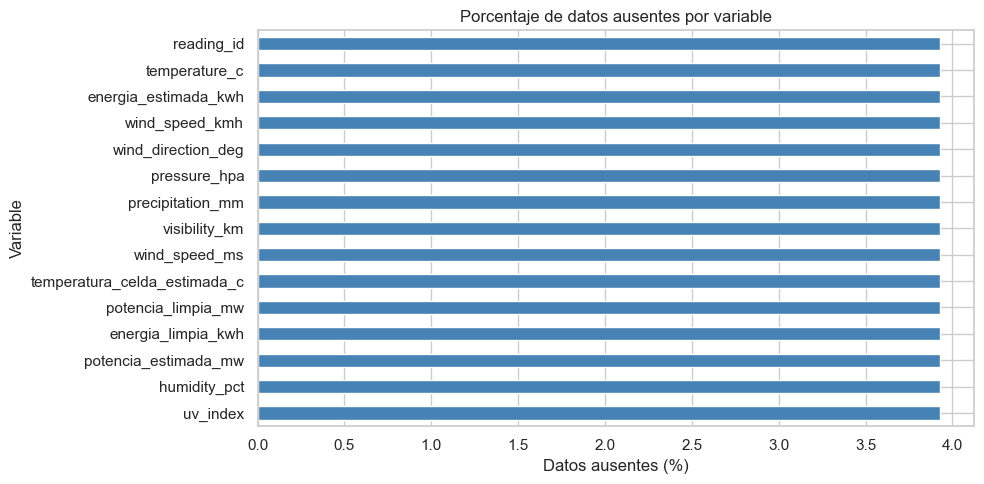

,filas
reading_available,
True,211344
False,8640


Temperatura ausente,False,True
reading_available,,
False,0,8640
True,211344,0


In [5]:
faltantes = pd.DataFrame({
    "ausentes": datos_originales.isna().sum(),
    "porcentaje": datos_originales.isna().mean() * 100
}).sort_values("ausentes", ascending=False)
display(faltantes.round(2))

faltantes[faltantes["ausentes"] > 0]["porcentaje"].plot.barh(color="steelblue")
plt.title("Porcentaje de datos ausentes por variable")
plt.xlabel("Datos ausentes (%)")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

display(datos["reading_available"].value_counts(dropna=False).rename("filas").to_frame())
display(pd.crosstab(datos["reading_available"], datos["temperature_c"].isna(),
                    colnames=["Temperatura ausente"]))


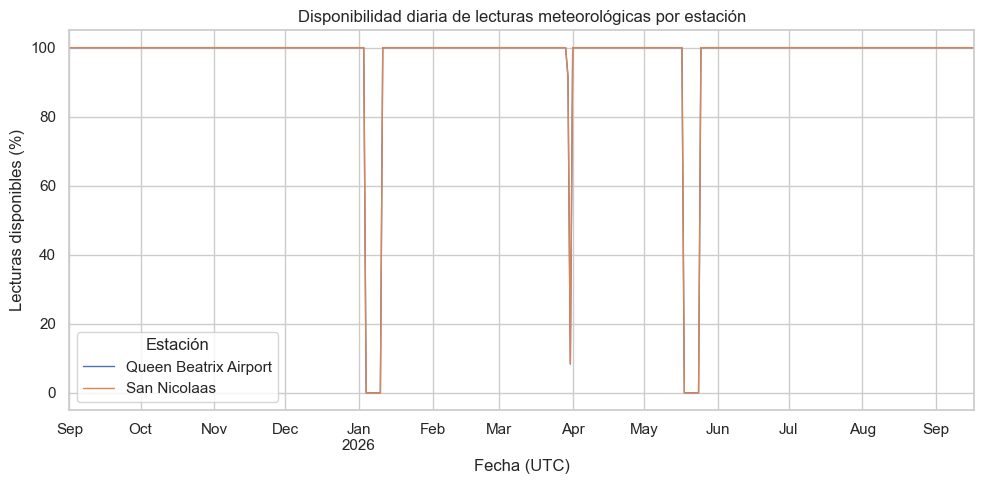

Filas originales duplicadas: 0
Claves estación-fecha duplicadas: 0
Fechas no válidas: 0
Fechas de origen no válidas: 0


,intervalos
timestamp,
0 days 00:05:00,219982


In [6]:
# El porcentaje diario permite ver si los ausentes se concentran en periodos completos.
disponibilidad = datos.groupby(["station_name", pd.Grouper(key="timestamp", freq="D")])[
    "reading_available"
].mean().unstack("station_name") * 100

disponibilidad.plot(linewidth=1)
plt.title("Disponibilidad diaria de lecturas meteorológicas por estación")
plt.xlabel("Fecha (UTC)")
plt.ylabel("Lecturas disponibles (%)")
plt.ylim(-5, 105)
plt.legend(title="Estación")
plt.tight_layout()
plt.show()

print("Filas originales duplicadas:", datos_originales.duplicated().sum())
print("Claves estación-fecha duplicadas:", datos.duplicated(["station_id", "timestamp"]).sum())
print("Fechas no válidas:", datos["timestamp"].isna().sum())
print("Fechas de origen no válidas:", datos["radiation_source_timestamp"].isna().sum())

datos = datos.sort_values(["station_id", "timestamp"]).reset_index(drop=True)
intervalos = datos.groupby("station_id")["timestamp"].diff()
display(intervalos.value_counts().rename("intervalos").to_frame())


Hay **8.640 filas sin lectura meteorológica (3,93 %)**. Afectan a las ocho variables
meteorológicas y a `reading_id`; la radiación está disponible en todas las filas.
Los ausentes se concentran en varios bloques, incluidos enero y mayo de 2026.
No encontramos duplicados de fila ni de estación-fecha y la rejilla temporal es de cinco minutos.
Esto no significa que todas las filas tengan una medición meteorológica real.

**Decisión:** no rellenamos huecos de varios días ni cambiamos ausentes por ceros.
Conservamos las filas con radiación para estudiar su evolución. En las relaciones meteorológicas
usamos las lecturas disponibles y en cada cálculo se descartan únicamente los ausentes necesarios.


In [7]:
meteorologicas = ["temperature_c", "humidity_pct", "wind_speed_kmh", "wind_direction_deg",
                  "pressure_hpa", "precipitation_mm", "visibility_km", "uv_index"]
solares = [objetivo, "direct_normal_irradiance_instant", "diffuse_radiation_instant",
           "direct_radiation_instant", "cloud_cover", "sunshine_duration_source_s"]

display(datos[meteorologicas + solares].describe().T.round(2))

rangos = pd.Series({
    "Humedad fuera de 0-100 %": ((datos["humidity_pct"] < 0) | (datos["humidity_pct"] > 100)).sum(),
    "Nubosidad fuera de 0-100 %": ((datos["cloud_cover"] < 0) | (datos["cloud_cover"] > 100)).sum(),
    "Dirección fuera de 0-360 grados": ((datos["wind_direction_deg"] < 0) | (datos["wind_direction_deg"] > 360)).sum(),
    "Velocidad del viento negativa": (datos["wind_speed_kmh"] < 0).sum(),
    "Precipitación negativa": (datos["precipitation_mm"] < 0).sum(),
    "Radiación total negativa": (datos[objetivo] < 0).sum(),
    "Radiación positiva con is_day=0": ((datos["is_day"] == 0) & (datos[objetivo] > 0)).sum(),
    "Radiación cero con is_day=1": ((datos["is_day"] == 1) & (datos[objetivo] == 0)).sum()
}, name="filas")
display(rangos.to_frame())

# El criterio IQR sirve para señalar valores extremos, no para borrarlos automáticamente.
q1 = datos[meteorologicas].quantile(0.25)
q3 = datos[meteorologicas].quantile(0.75)
iqr = q3 - q1
extremos = ((datos[meteorologicas] < q1 - 1.5 * iqr) |
            (datos[meteorologicas] > q3 + 1.5 * iqr)).sum()
display(extremos.rename("posibles_extremos_IQR").to_frame())


,count,mean,std,min,25%,50%,75%,max
temperature_c,211344.0,28.35,2.83,20.8,26.0,28.4,30.70,34.9
humidity_pct,211344.0,77.11,6.92,63.4,70.9,77.2,82.10,100.0
wind_speed_kmh,211344.0,22.74,2.86,13.2,20.9,22.9,24.70,51.5
wind_direction_deg,211344.0,44.80,6.04,17.8,41.3,44.8,48.30,72.8
pressure_hpa,211344.0,1014.37,1.33,997.6,1013.4,1014.3,1015.50,1017.0
precipitation_mm,211344.0,0.01,0.23,0.0,0.0,0.0,0.00,20.3
visibility_km,211344.0,11.99,0.35,0.5,11.8,12.0,12.20,13.3
uv_index,211344.0,2.54,3.10,0.0,0.0,0.0,5.70,9.1
shortwave_radiation_instant,219984.0,262.18,336.47,0.0,0.0,0.0,571.32,1004.0
direct_normal_irradiance_instant,219984.0,292.70,342.63,0.0,0.0,0.0,662.70,973.7


,filas
Humedad fuera de 0-100 %,0
Nubosidad fuera de 0-100 %,0
Dirección fuera de 0-360 grados,0
Velocidad del viento negativa,0
Precipitación negativa,0
Radiación total negativa,0
Radiación positiva con is_day=0,0
Radiación cero con is_day=1,1428


,posibles_extremos_IQR
temperature_c,0
humidity_pct,91
wind_speed_kmh,1254
wind_direction_deg,6410
pressure_hpa,818
precipitation_mm,895
visibility_km,3278
uv_index,0


La temperatura va de 20,8 a 34,9 °C y la radiación total de 0 a 1.004 en las unidades del archivo.
Los ceros nocturnos de radiación son esperables. También hay 1.428 filas marcadas como diurnas
con radiación cero, que conviene revisar en los cambios de día/noche y en la fuente horaria.

La precipitación tiene los cuartiles a cero: con el criterio IQR cualquier lluvia puede quedar
marcada como extrema. No la eliminamos por ello. Los valores poco frecuentes de presión,
viento o visibilidad también se conservan hasta comprobar su origen.


## 3. Revisión del cruce de datos solares
Antes de interpretar relaciones, comprobamos cuántas mediciones solares distintas hay realmente.


In [8]:
display(datos["radiation_quality"].value_counts().rename("filas").to_frame())

grupos_origen = datos.groupby(["station_id", "radiation_source_timestamp"]).agg(
    filas=(objetivo, "size"),
    valores_radiacion=(objetivo, "nunique")
)
display(grupos_origen.value_counts().rename("grupos").to_frame())

datos["minutos_desde_origen"] = (
    datos["timestamp"] - datos["radiation_source_timestamp"]
).dt.total_seconds() / 60
display(datos["minutos_desde_origen"].describe().to_frame())

# Una observación por estación y hora de origen para las comparaciones descriptivas.
# La meteorología se resume con su media dentro de esa hora.
agregacion = {variable: "mean" for variable in meteorologicas}
agregacion.update({variable: "first" for variable in solares})
agregacion.update({"station_name": "first", "is_day": "first"})
datos_hora = datos.groupby(["station_id", "radiation_source_timestamp"], as_index=False).agg(agregacion)
datos_hora["fecha_local"] = datos_hora["radiation_source_timestamp"].dt.tz_convert(zona_aruba)
datos_hora["hora"] = datos_hora["fecha_local"].dt.hour
datos_hora["mes"] = datos_hora["fecha_local"].dt.strftime("%Y-%m")
datos_hora_dia = datos_hora[datos_hora["is_day"] == 1].copy()

print("Filas de cinco minutos:", len(datos))
print("Grupos estación-hora de origen:", len(datos_hora))
print("Grupos diurnos:", len(datos_hora_dia))


,filas
radiation_quality,
repetido_desde_hora,219984


,,grupos
filas,valores_radiacion,
12,1,18332


,minutos_desde_origen
count,219984.000000
mean,27.500000
std,17.260302
min,0.000000
25%,13.750000
50%,27.500000
75%,41.250000
max,55.000000


Filas de cinco minutos: 219984
Grupos estación-hora de origen: 18332
Grupos diurnos: 9227


Todas las filas llevan la etiqueta `repetido_desde_hora`. Hay **18.332 grupos estación-hora**
y cada grupo contiene doce filas con el mismo valor de radiación. La rejilla de cinco minutos
no aporta doce mediciones solares independientes por hora.

Usaremos la serie de cinco minutos para observar los escalones y preparar los retardos.
Para las principales relaciones con la meteorología trabajaremos por hora de origen y
separaremos el periodo diurno. Las medias meteorológicas horarias son solo un resumen para
este EDA: no deben utilizarse para predecir desde el principio de una hora, porque incluirían
lecturas posteriores al instante de predicción.

La fecha de origen identifica el periodo del dato, pero no demuestra cuándo estaba disponible
en tiempo real. Esa disponibilidad tendrá que comprobarse antes del modelado.


## 4. Distribución de la radiación y de las variables meteorológicas
Separamos día y noche para que la acumulación de ceros no oculte la variabilidad diurna.


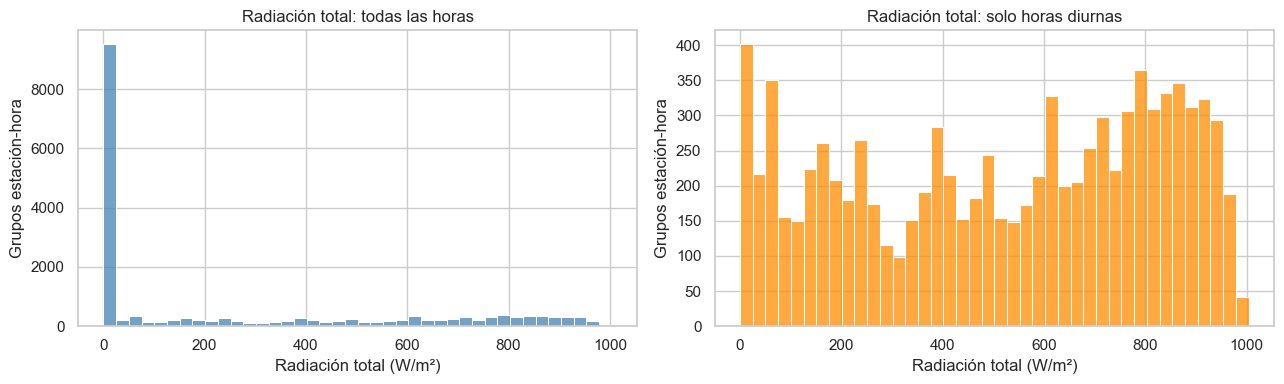

,count,mean,median,min,max
is_day,,,,,
0.0,9105,0.0,0.0,0.0,0.0
1.0,9227,520.9,568.9,0.0,1004.0


In [9]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=datos_hora, x=objetivo, bins=40, ax=ejes[0], color="steelblue")
ejes[0].set_title("Radiación total: todas las horas")
sns.histplot(data=datos_hora_dia, x=objetivo, bins=40, ax=ejes[1], color="darkorange")
ejes[1].set_title("Radiación total: solo horas diurnas")
for eje in ejes:
    eje.set_xlabel("Radiación total (W/m²)")
    eje.set_ylabel("Grupos estación-hora")
plt.tight_layout()
plt.show()

display(datos_hora.groupby("is_day")[objetivo].agg(["count", "mean", "median", "min", "max"]).round(2))


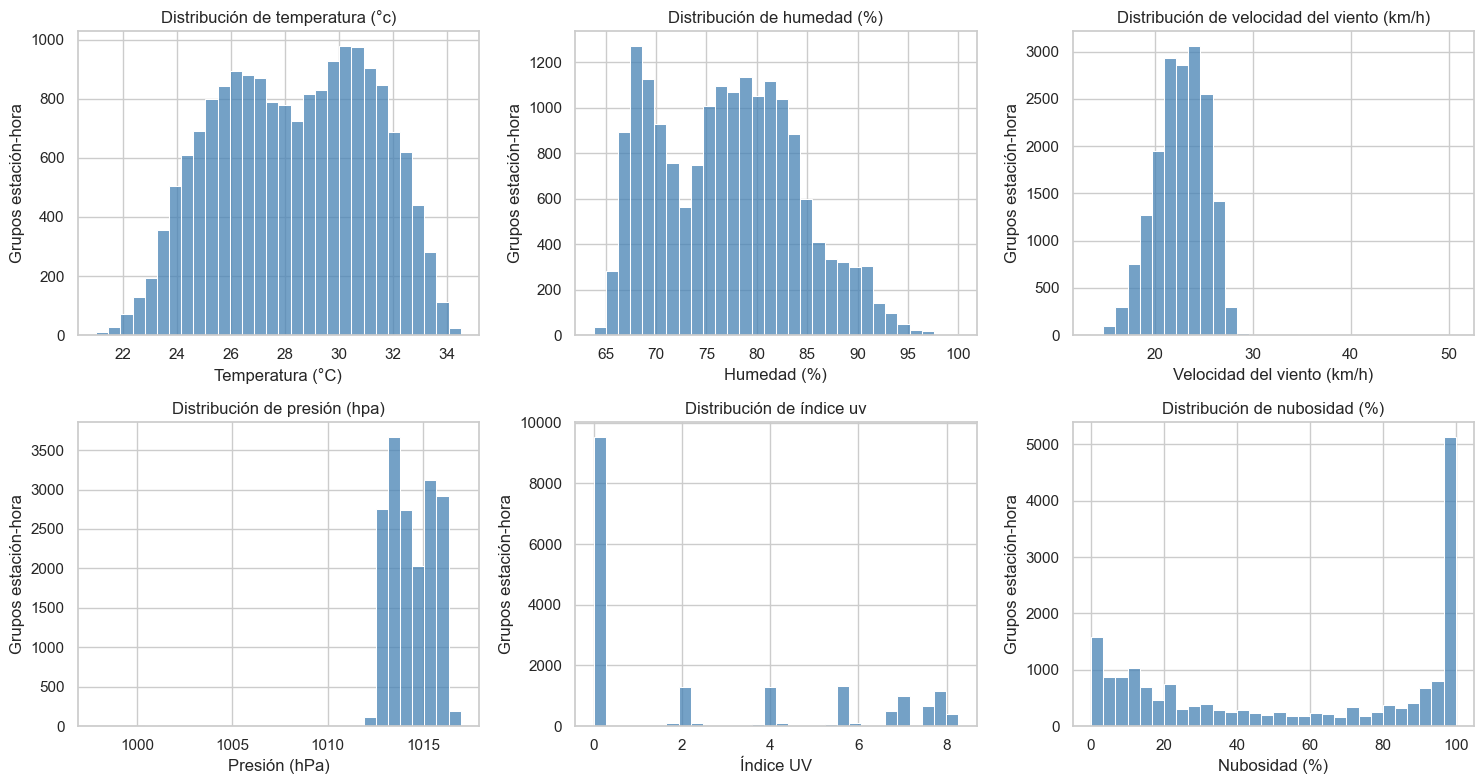

In [10]:
variables_distribucion = ["temperature_c", "humidity_pct", "wind_speed_kmh", "pressure_hpa", "uv_index", "cloud_cover"]
etiquetas = {
    "temperature_c": "Temperatura (°C)",
    "humidity_pct": "Humedad (%)",
    "wind_speed_kmh": "Velocidad del viento (km/h)",
    "wind_direction_deg": "Dirección del viento (grados)",
    "pressure_hpa": "Presión (hPa)",
    "precipitation_mm": "Precipitación (mm)",
    "visibility_km": "Visibilidad (km)",
    "uv_index": "Índice UV",
    "cloud_cover": "Nubosidad (%)"
}

fig, ejes = plt.subplots(2, 3, figsize=(15, 8))
for variable, eje in zip(variables_distribucion, ejes.flat):
    sns.histplot(data=datos_hora, x=variable, bins=30, ax=eje, color="steelblue")
    eje.set_title("Distribución de " + etiquetas[variable].lower())
    eje.set_xlabel(etiquetas[variable])
    eje.set_ylabel("Grupos estación-hora")
plt.tight_layout()
plt.show()


Los ceros tienen mucho peso en la distribución de radiación al incluir las horas nocturnas.
En las filas diurnas de cinco minutos la radiación media ronda 521 W/m². Por eso compararemos
las correlaciones globales con las diurnas: una relación puede deberse en parte al ciclo día/noche.


## 5. Evolución temporal y diferencias entre estaciones
Revisamos el perfil horario, la evolución diaria y las diferencias por mes y estación.
No calculamos producción eléctrica a partir de estas medias de radiación.


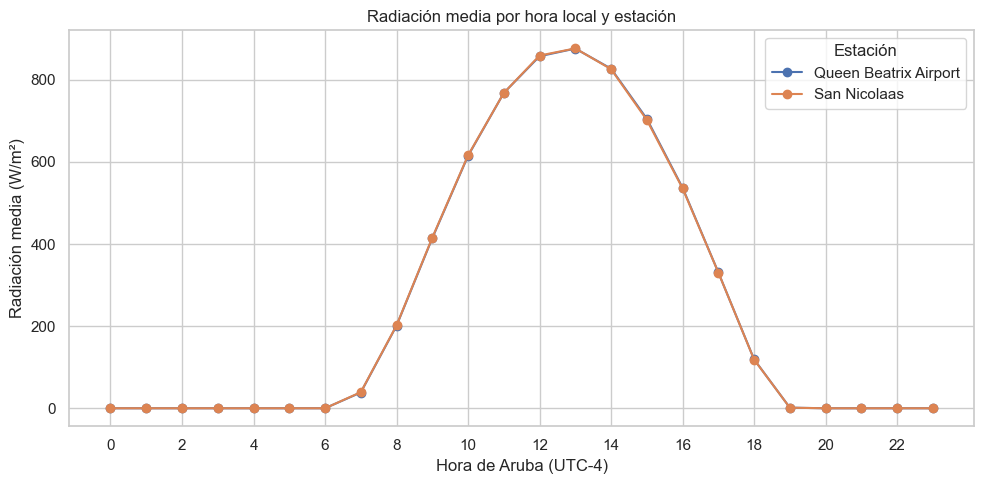

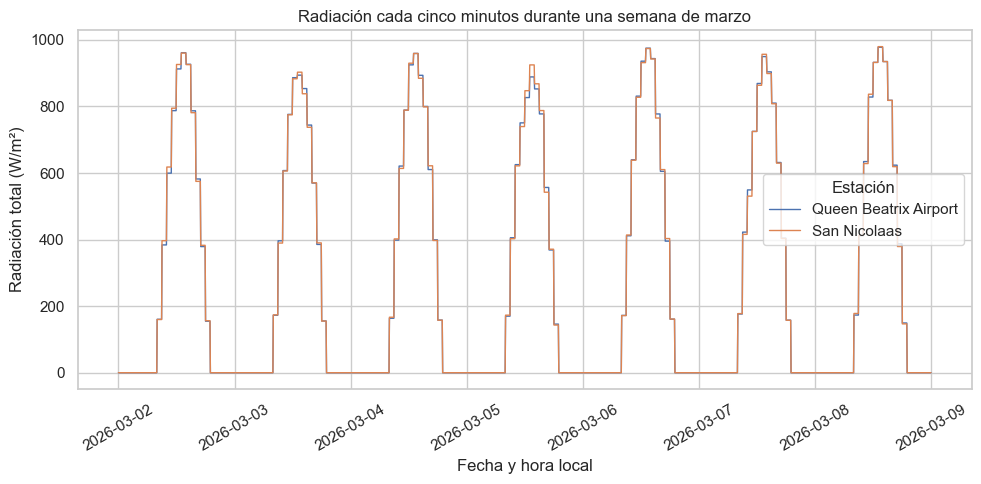

In [11]:
perfil = datos_hora.groupby(["hora", "station_name"])[objetivo].mean().unstack("station_name")
perfil.plot(marker="o")
plt.title("Radiación media por hora local y estación")
plt.xlabel("Hora de Aruba (UTC-4)")
plt.ylabel("Radiación media (W/m²)")
plt.xticks(range(0, 24, 2))
plt.legend(title="Estación")
plt.tight_layout()
plt.show()

# Mostramos una semana para apreciar la repetición horaria en la rejilla de cinco minutos.
semana = datos[(datos["fecha_local"] >= "2026-03-02") &
               (datos["fecha_local"] < "2026-03-09")]
for estacion, grupo in semana.groupby("station_name"):
    plt.plot(grupo["fecha_local"], grupo[objetivo], label=estacion, linewidth=1)
plt.title("Radiación cada cinco minutos durante una semana de marzo")
plt.xlabel("Fecha y hora local")
plt.ylabel("Radiación total (W/m²)")
plt.legend(title="Estación")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


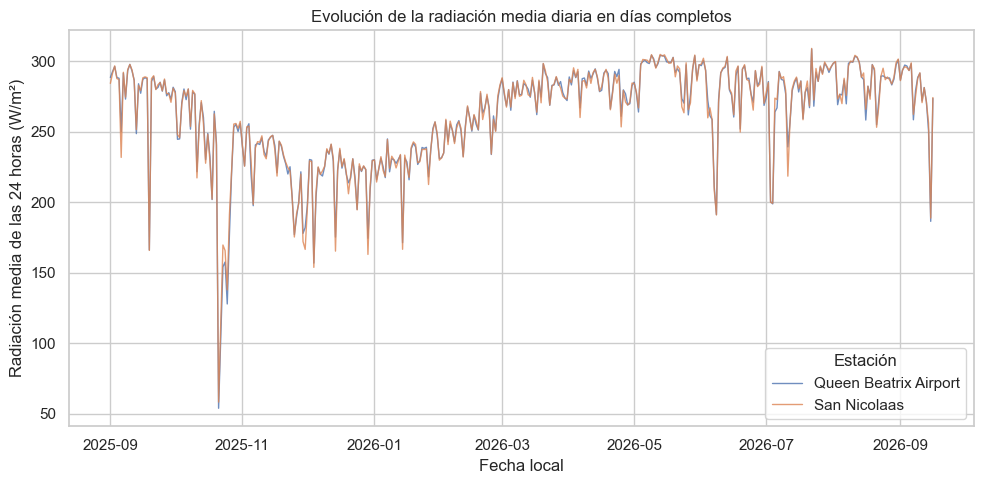

count    mean
mes     station_name                        
2025-09 Queen Beatrix Airport    360  558.55
        San Nicolaas             360  557.65
2025-10 Queen Beatrix Airport    372  459.39
        San Nicolaas             372  463.11
2025-11 Queen Beatrix Airport    360  451.37
        San Nicolaas             360  450.27
2025-12 Queen Beatrix Airport    369  438.67
        San Nicolaas             370  436.37
2026-01 Queen Beatrix Airport    341  503.05
        San Nicolaas             341  502.31
2026-02 Queen Beatrix Airport    317  542.74
        San Nicolaas             318  540.74
2026-03 Queen Beatrix Airport    372  560.18
        San Nicolaas             372  559.93
2026-04 Queen Beatrix Airport    360  568.36
        San Nicolaas             360  565.96
2026-05 Queen Beatrix Airport    380  573.54
        San Nicolaas             378  576.30
2026-06 Queen Beatrix Airport    390  513.29
        San Nicolaas             390  512.73
2026-07 Queen Beatrix Airport    403  509.78
        San Nicolaas             403  511.30
2026-08 Queen Beatrix Airport    387  552.33
        San Nicolaas             386  554.85
2026-09 Queen Beatrix Airport    203  556.82
        San Nicolaas             203  557.43

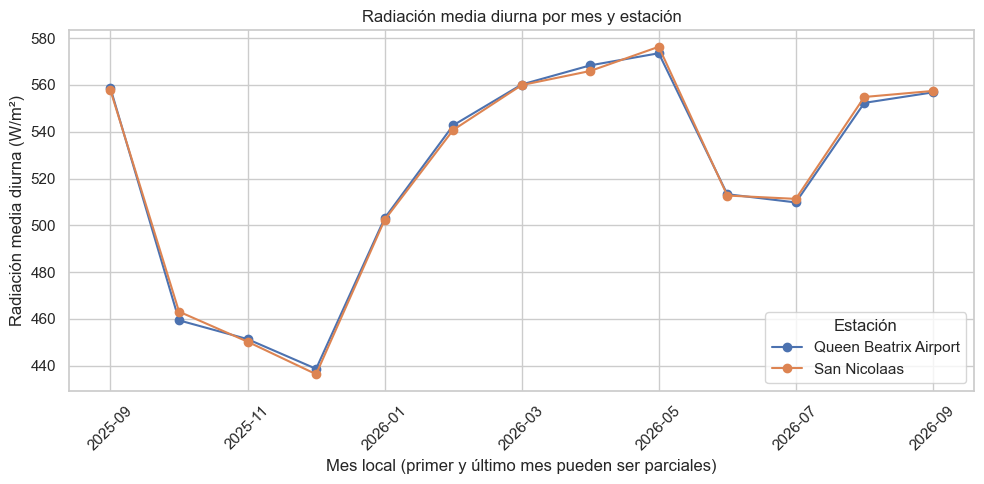

In [12]:
# Excluimos los días locales incompletos de la media diaria.
diario = datos.groupby(["station_name", pd.Grouper(key="fecha_local", freq="D")]).agg(
    radiacion_media=(objetivo, "mean"),
    filas=(objetivo, "size")
).reset_index()
diario_completo = diario[diario["filas"] == 288]

for estacion, grupo in diario_completo.groupby("station_name"):
    plt.plot(grupo["fecha_local"], grupo["radiacion_media"], label=estacion, linewidth=1, alpha=0.8)
plt.title("Evolución de la radiación media diaria en días completos")
plt.xlabel("Fecha local")
plt.ylabel("Radiación media de las 24 horas (W/m²)")
plt.legend(title="Estación")
plt.tight_layout()
plt.show()

mensual = datos_hora_dia.groupby(["mes", "station_name"])[objetivo].agg(["count", "mean"]).round(2)
display(mensual)
mensual["mean"].unstack("station_name").plot(marker="o")
plt.title("Radiación media diurna por mes y estación")
plt.xlabel("Mes local (primer y último mes pueden ser parciales)")
plt.ylabel("Radiación media diurna (W/m²)")
plt.xticks(rotation=45)
plt.legend(title="Estación")
plt.tight_layout()
plt.show()


,count,mean,median,std,max
station_name,,,,,
Queen Beatrix Airport,4614,520.86,570.25,300.16,1001.1
San Nicolaas,4613,520.93,565.90,300.43,1004.0


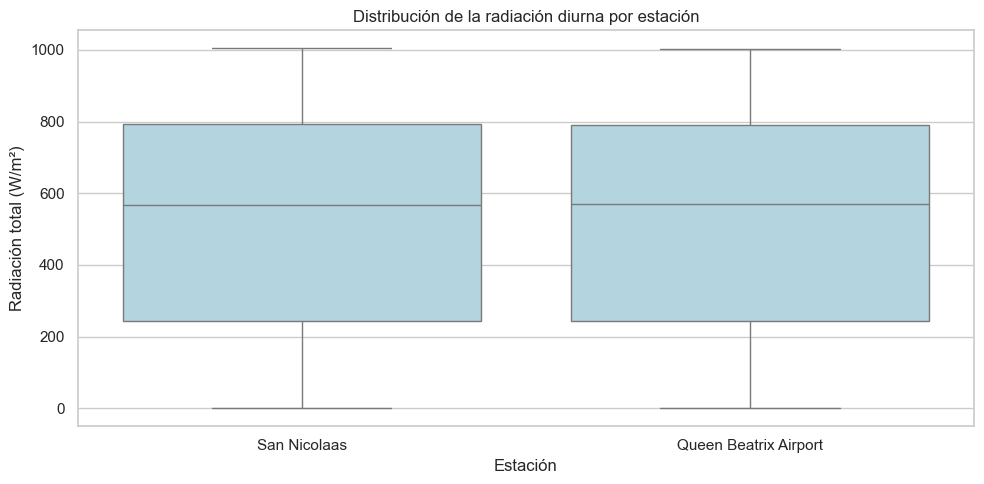

In [13]:
display(datos_hora_dia.groupby("station_name")[objetivo].agg(["count", "mean", "median", "std", "max"]).round(2))
sns.boxplot(data=datos_hora_dia, x="station_name", y=objetivo, color="lightblue")
plt.title("Distribución de la radiación diurna por estación")
plt.xlabel("Estación")
plt.ylabel("Radiación total (W/m²)")
plt.tight_layout()
plt.show()


Las medias de radiación de las dos estaciones son muy próximas: en las filas originales
son 262,17 y 262,19 W/m² al incluir noche y día. El máximo del perfil medio aparece alrededor
de las 13:00 locales. La forma escalonada de la serie refleja la repetición de datos horarios.

Hay solo dos ubicaciones. No podemos separar con estos datos un efecto de la altitud o de
las coordenadas del efecto propio de cada estación. Además, las diferencias entre ambas
pueden depender de cómo se obtuvo la radiación y no solo del microclima.


## 6. Relaciones de la meteorología con la radiación
Comenzamos con correlaciones y después vemos las relaciones una a una. Pearson resume
relaciones lineales y Spearman compara el orden de los valores. Ninguna demuestra causalidad.
Los recuentos indican cuántas parejas válidas se usaron.


,Pearson_5min_todas,Pearson_hora_todas,Pearson_hora_dia,Spearman_hora_dia,parejas_hora_dia
temperature_c,-0.548,-0.550,-0.258,-0.210,8880
humidity_pct,0.497,0.498,0.189,0.158,8880
wind_speed_kmh,-0.646,-0.650,-0.396,-0.441,8880
pressure_hpa,0.024,0.024,0.056,0.057,8880
precipitation_mm,-0.001,-0.005,-0.009,-0.024,8880
visibility_km,0.001,0.003,-0.005,-0.009,8880
uv_index,0.123,0.124,-0.196,-0.110,8880
cloud_cover,-0.060,-0.060,-0.091,-0.091,9227


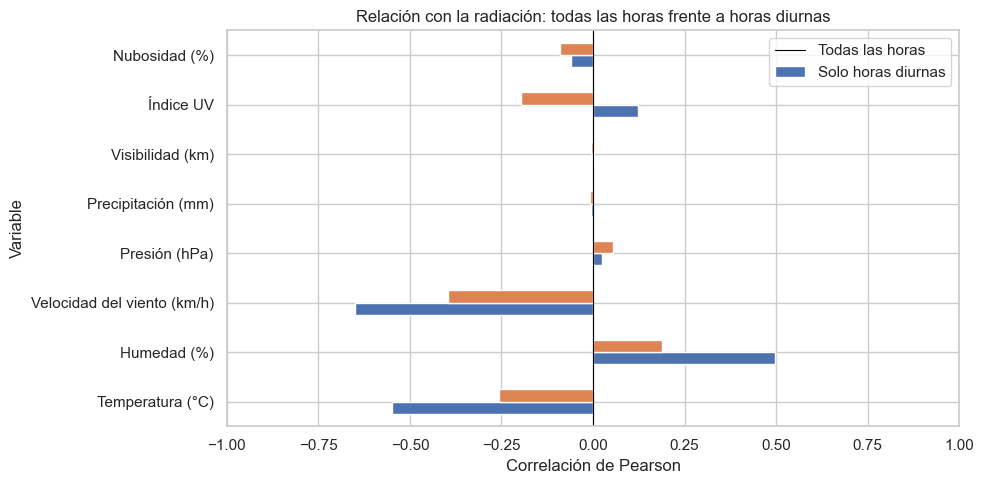

In [14]:
predictoras = ["temperature_c", "humidity_pct", "wind_speed_kmh", "pressure_hpa",
               "precipitation_mm", "visibility_km", "uv_index", "cloud_cover"]

relaciones = pd.DataFrame({
    "Pearson_5min_todas": datos[predictoras].corrwith(datos[objetivo]),
    "Pearson_hora_todas": datos_hora[predictoras].corrwith(datos_hora[objetivo]),
    "Pearson_hora_dia": datos_hora_dia[predictoras].corrwith(datos_hora_dia[objetivo]),
    "Spearman_hora_dia": datos_hora_dia[predictoras + [objetivo]].corr(method="spearman")[objetivo].reindex(predictoras),
    "parejas_hora_dia": datos_hora_dia[predictoras].notna().sum()
})
display(relaciones.round(3))

relaciones[["Pearson_hora_todas", "Pearson_hora_dia"]].rename(index=etiquetas).plot.barh()
plt.title("Relación con la radiación: todas las horas frente a horas diurnas")
plt.xlabel("Correlación de Pearson")
plt.ylabel("Variable")
plt.xlim(-1, 1)
plt.axvline(0, color="black", linewidth=0.8)
plt.legend(["Todas las horas", "Solo horas diurnas"])
plt.tight_layout()
plt.show()


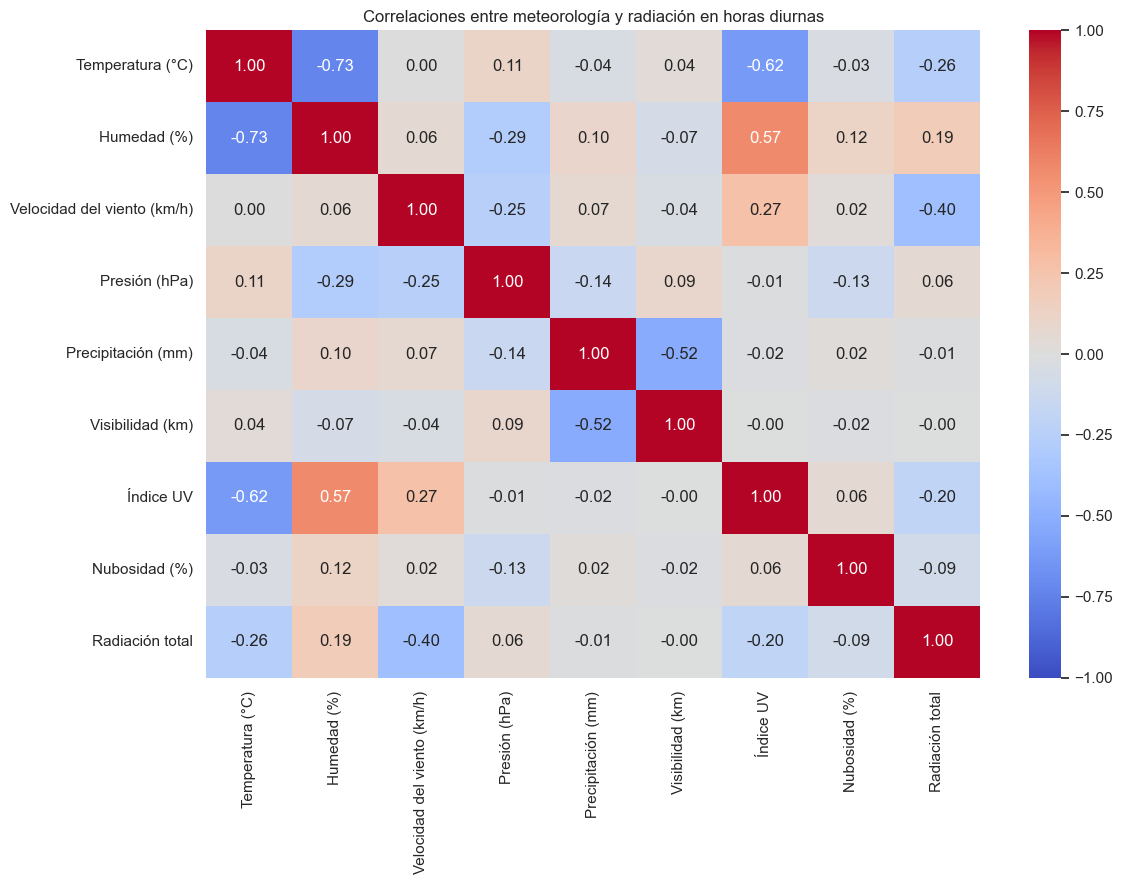

In [15]:
matriz = datos_hora_dia[predictoras + [objetivo]].corr()
matriz = matriz.rename(index=etiquetas, columns=etiquetas)
matriz = matriz.rename(index={objetivo: "Radiación total"}, columns={objetivo: "Radiación total"})
plt.figure(figsize=(12, 9))
sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlaciones entre meteorología y radiación en horas diurnas")
plt.tight_layout()
plt.show()


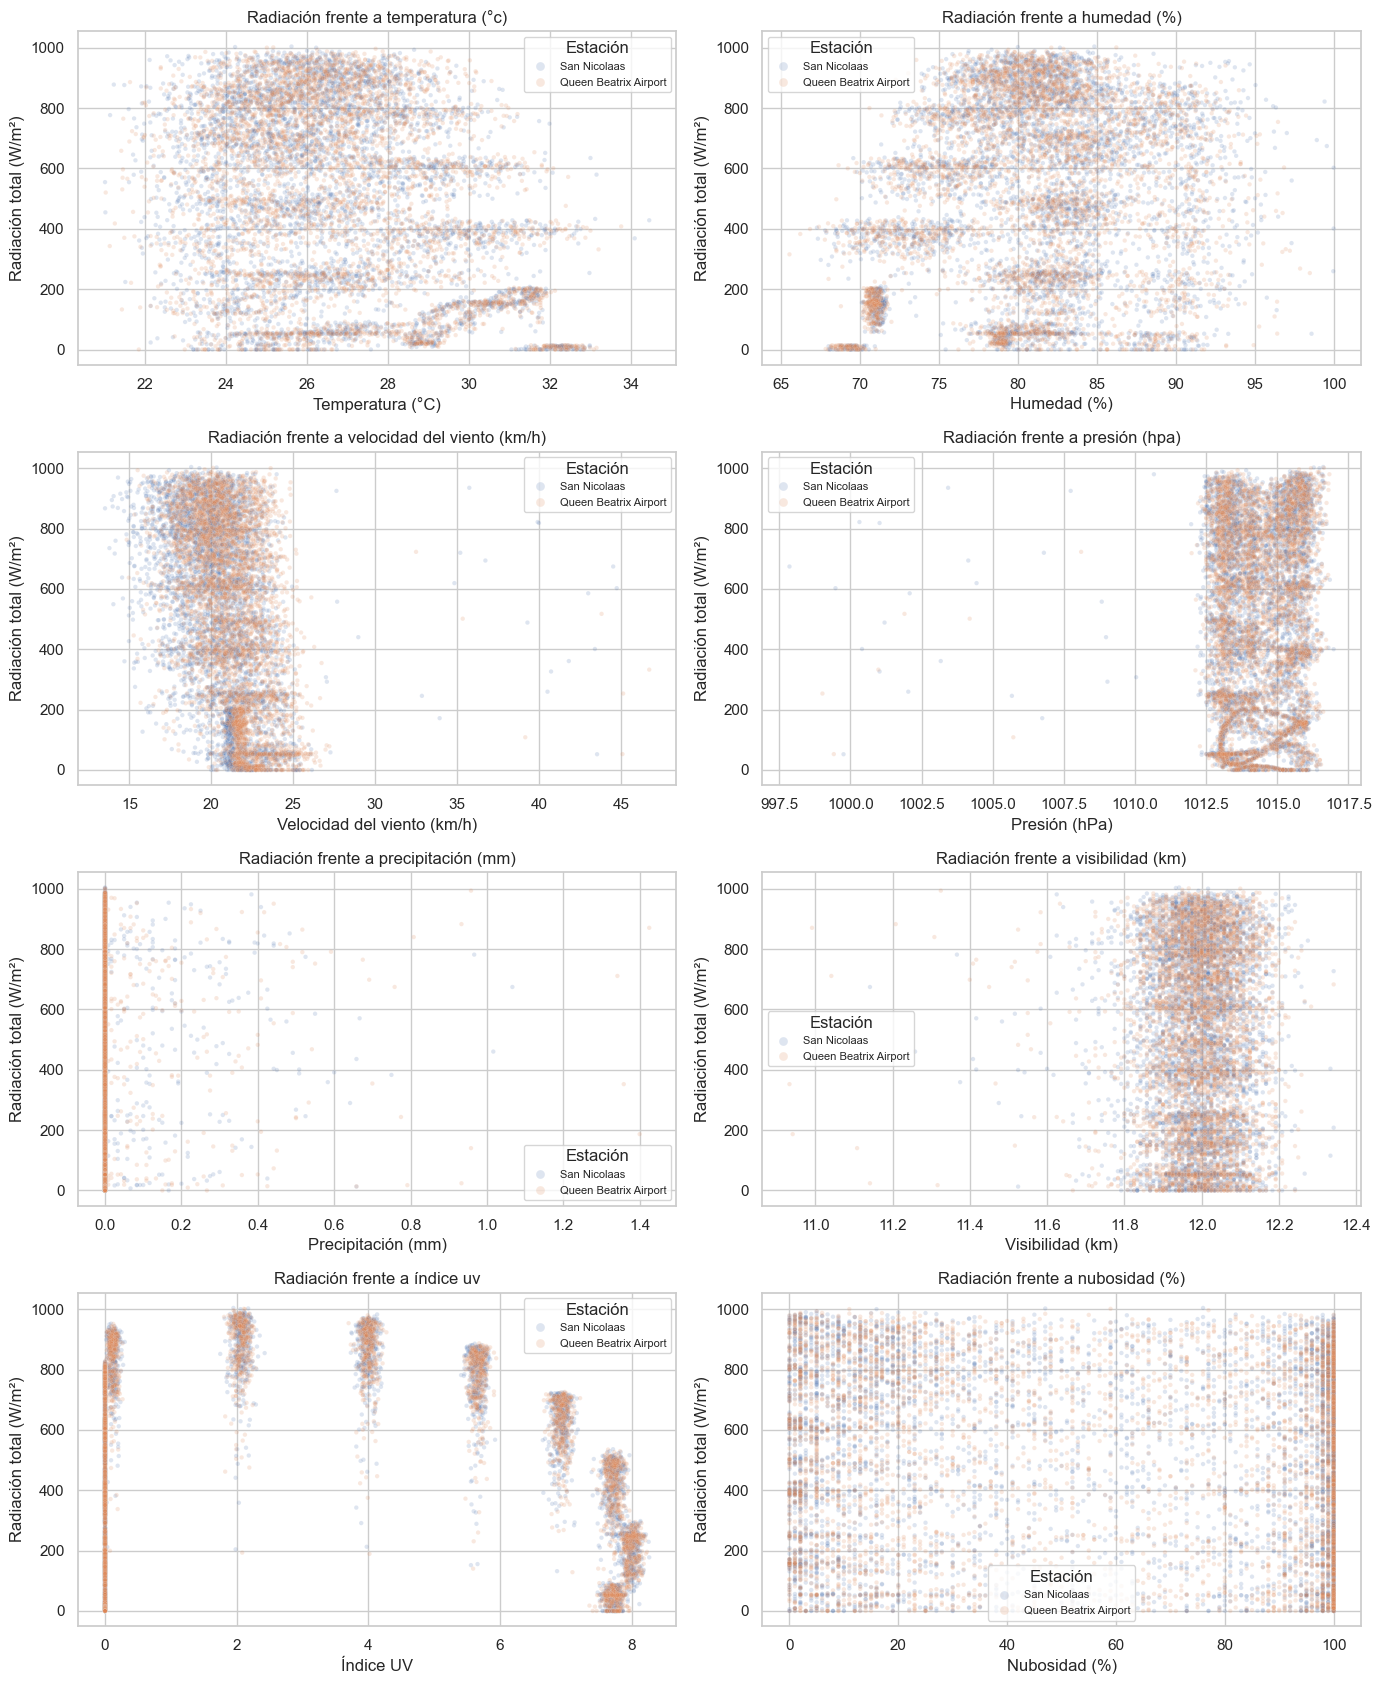

In [16]:
# Usamos todos los grupos horarios diurnos; alpha ayuda a ver dónde se concentran.
fig, ejes = plt.subplots(4, 2, figsize=(14, 17))
for variable, eje in zip(predictoras, ejes.flat):
    sns.scatterplot(data=datos_hora_dia, x=variable, y=objetivo,
                    hue="station_name", alpha=0.18, s=10, ax=eje)
    eje.set_title("Radiación frente a " + etiquetas[variable].lower())
    eje.set_xlabel(etiquetas[variable])
    eje.set_ylabel("Radiación total (W/m²)")
    eje.legend(title="Estación", markerscale=2, fontsize=8)
plt.tight_layout()
plt.show()


En las filas de cinco minutos, temperatura y viento presentan correlaciones negativas con
la radiación (aproximadamente -0,55 y -0,65), mientras que la humedad presenta una correlación
positiva (0,50). Al considerar solo el día, estas asociaciones se reducen.

Estos signos no bastan para afirmar que una temperatura más baja produzca más radiación o
que una mayor humedad la favorezca. Pueden intervenir la hora, el cruce de fuentes y el
periodo del año. El índice UV también muestra una relación llamativamente débil en el
conjunto completo. Revisamos los perfiles horarios antes de sacar conclusiones.

La dirección del viento no se incluye en la correlación lineal principal porque es una
variable circular: 0 y 360 grados representan la misma dirección.


### 6.1 Comprobación de la alineación entre UV y radiación
Comparamos la forma de los perfiles, dividiendo cada variable por su máximo horario.
Así se ven en una escala común; el gráfico no compara sus unidades originales.


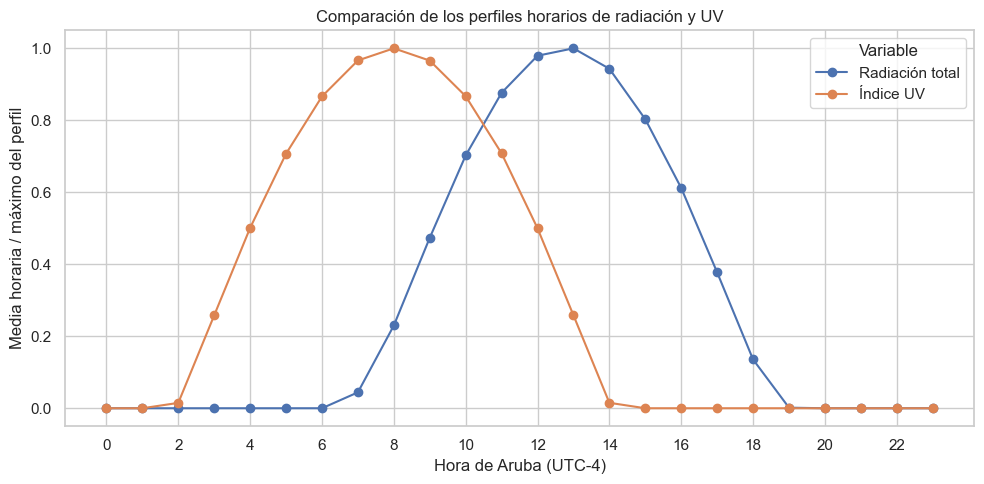

Hora local del máximo medio de radiación: 13
Hora local del máximo medio de UV: 8
Filas con UV positivo y is_day=0: 40167


In [17]:
perfil_comparado = datos_hora.groupby("hora")[[objetivo, "uv_index"]].mean()
perfil_normalizado = perfil_comparado / perfil_comparado.max()
perfil_normalizado.rename(columns={objetivo: "Radiación total", "uv_index": "Índice UV"}).plot(marker="o")
plt.title("Comparación de los perfiles horarios de radiación y UV")
plt.xlabel("Hora de Aruba (UTC-4)")
plt.ylabel("Media horaria / máximo del perfil")
plt.xticks(range(0, 24, 2))
plt.legend(title="Variable")
plt.tight_layout()
plt.show()

print("Hora local del máximo medio de radiación:", perfil_comparado[objetivo].idxmax())
print("Hora local del máximo medio de UV:", perfil_comparado["uv_index"].idxmax())
print("Filas con UV positivo y is_day=0:", ((datos["uv_index"] > 0) & (datos["is_day"] == 0)).sum())


El máximo medio de UV aparece a las **08:00 locales** y el de radiación a las **13:00**.
La separación de unas cinco horas y los valores de UV en periodos marcados como nocturnos
son una señal para revisar la alineación de las fuentes y el significado de sus fechas.
No desplazamos las series para hacerlas coincidir: primero hay que comprobar cómo se generó
el cruce y si las marcas temporales representan el mismo tipo de instante o periodo.
Cambiar la visualización de UTC a hora local no corrige un desfase entre dos fuentes.


### 6.2 Nubosidad y radiación a horas comparables
La hora modifica mucho la radiación. Comparamos bandas de nubosidad dentro de cada hora
para no mezclar, por ejemplo, una mañana nublada con un mediodía despejado.


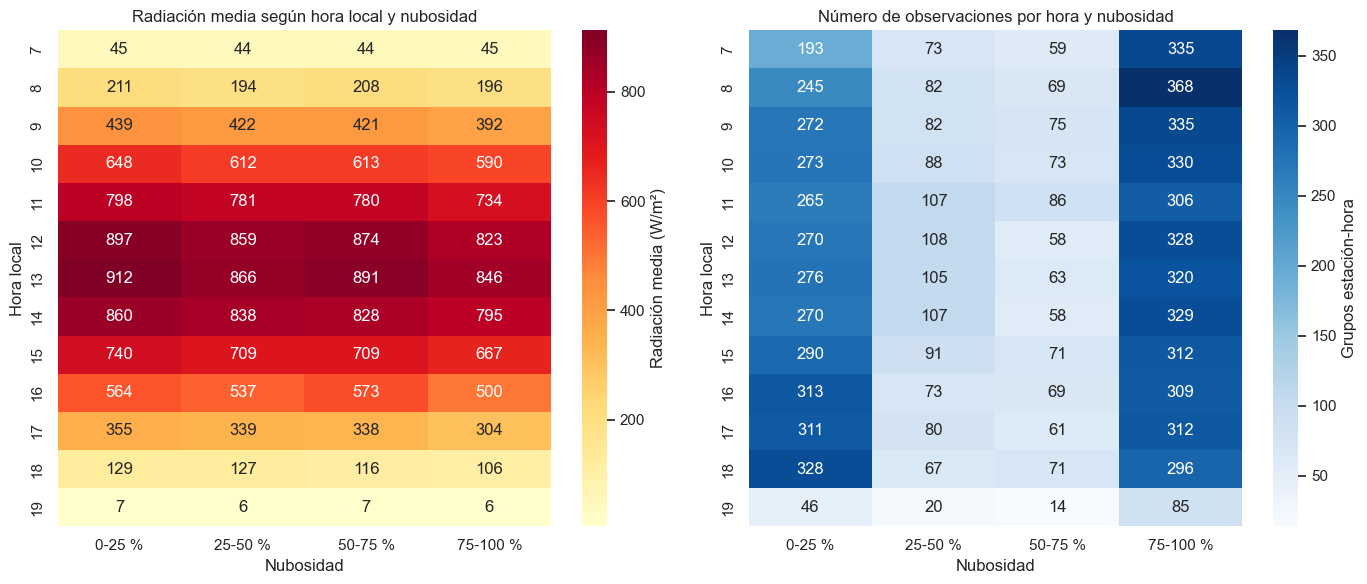

In [18]:
datos_hora_dia["grupo_nubes"] = pd.cut(
    datos_hora_dia["cloud_cover"], bins=[-0.1, 25, 50, 75, 100],
    labels=["0-25 %", "25-50 %", "50-75 %", "75-100 %"]
)
tabla_nubes = datos_hora_dia.pivot_table(index="hora", columns="grupo_nubes",
                                      values=objetivo, aggfunc="mean", observed=True)
recuento_nubes = datos_hora_dia.pivot_table(index="hora", columns="grupo_nubes",
                                         values=objetivo, aggfunc="count", observed=True)

fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(tabla_nubes, cmap="YlOrRd", annot=True, fmt=".0f", ax=ejes[0],
            cbar_kws={"label": "Radiación media (W/m²)"})
ejes[0].set_title("Radiación media según hora local y nubosidad")
sns.heatmap(recuento_nubes, cmap="Blues", annot=True, fmt=".0f", ax=ejes[1],
            cbar_kws={"label": "Grupos estación-hora"})
ejes[1].set_title("Número de observaciones por hora y nubosidad")
for eje in ejes:
    eje.set_xlabel("Nubosidad")
    eje.set_ylabel("Hora local")
plt.tight_layout()
plt.show()


El segundo gráfico permite comprobar cuánto respaldo tiene cada media. Las celdas con pocas
observaciones deben interpretarse con cuidado. Si la relación con nubosidad sigue siendo
débil a una misma hora, habrá que revisar la fuente y la correspondencia del cruce.


### 6.3 Lluvia, visibilidad y viento
La lluvia puede estar relacionada con las condiciones del cielo y también con la limpieza
de paneles. Aquí solo podemos estudiar su relación con la radiación, porque no tenemos
mediciones de suciedad ni producción de los paneles.


,count,mean,median
situacion,,,
Con lluvia,415,491.4,515.6
Sin lluvia,8465,521.6,569.6


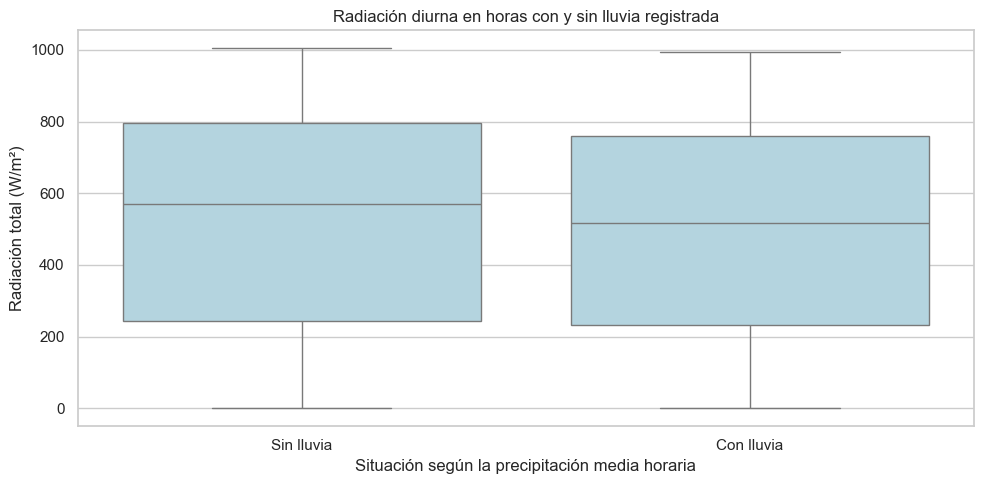

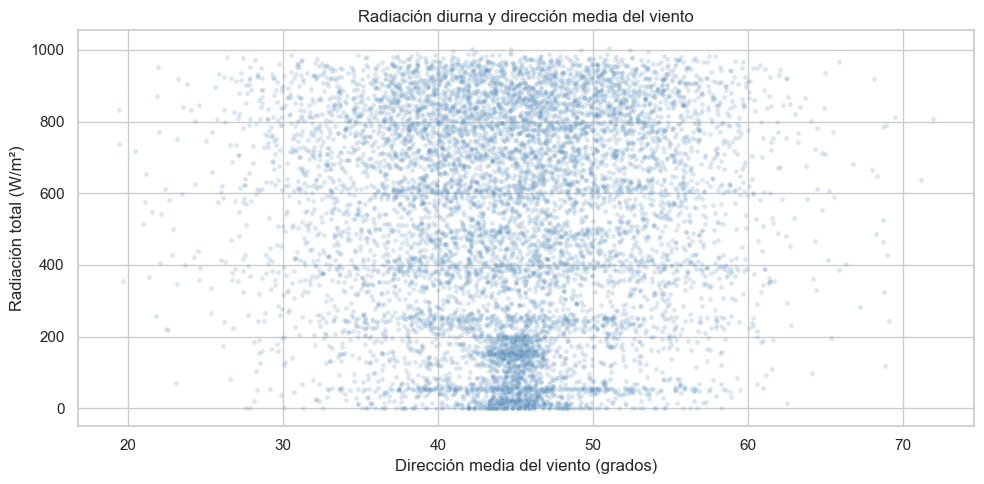

In [19]:
lluvia = datos_hora_dia.dropna(subset=["precipitation_mm"]).copy()
lluvia["situacion"] = "Sin lluvia"
lluvia.loc[lluvia["precipitation_mm"] > 0, "situacion"] = "Con lluvia"
display(lluvia.groupby("situacion")[objetivo].agg(["count", "mean", "median"]).round(2))

sns.boxplot(data=lluvia, x="situacion", y=objetivo, order=["Sin lluvia", "Con lluvia"], color="lightblue")
plt.title("Radiación diurna en horas con y sin lluvia registrada")
plt.xlabel("Situación según la precipitación media horaria")
plt.ylabel("Radiación total (W/m²)")
plt.tight_layout()
plt.show()

# La dirección se muestra en su escala original, sin tratarla como correlación lineal.
sns.scatterplot(data=datos_hora_dia, x="wind_direction_deg", y=objetivo,
                alpha=0.2, s=12, color="steelblue")
plt.title("Radiación diurna y dirección media del viento")
plt.xlabel("Dirección media del viento (grados)")
plt.ylabel("Radiación total (W/m²)")
plt.tight_layout()
plt.show()


La mayoría de registros no tiene lluvia y la visibilidad varía poco en buena parte de la serie.
Una correlación global pequeña no descarta diferencias en episodios concretos. La comparación
con/sin lluvia también puede reflejar diferencias de hora o estación. No demuestra un efecto
de lavado de los paneles. La dirección del viento del archivo se concentra entre unos 18 y 73
grados; dentro de ese rango su media aritmética sirve como resumen descriptivo.


## 7. Relación con las otras variables solares
Estas variables comparten información física con la radiación total. Una relación alta puede
ser esperable por su definición y no indicar una variable independiente útil para predecir.


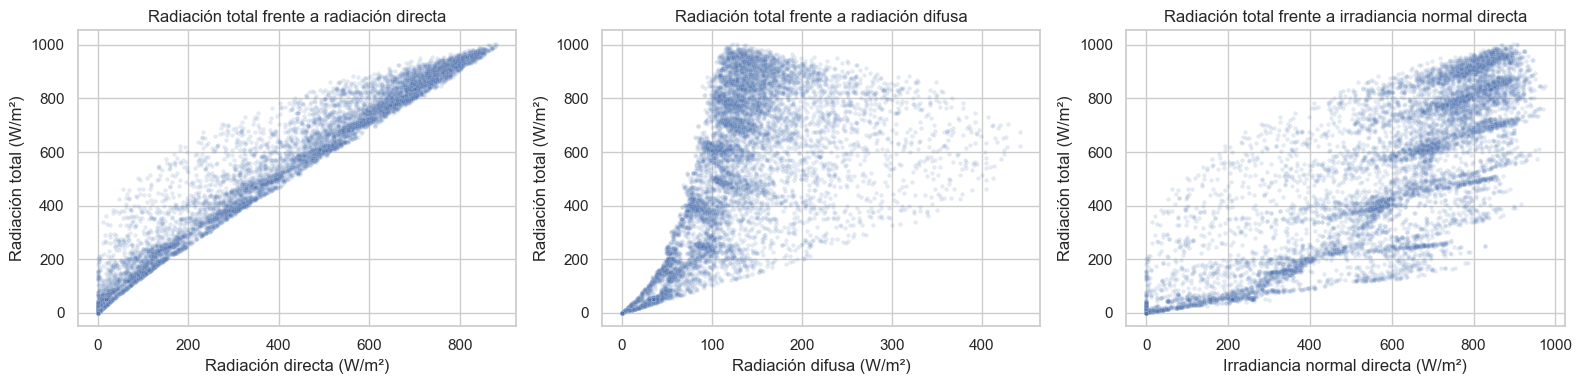

,shortwave_radiation_instant
shortwave_radiation_instant,1.000
direct_radiation_instant,0.978
diffuse_radiation_instant,0.600
direct_normal_irradiance_instant,0.816
sunshine_duration_source_s,0.501


,total_menos_directa_y_difusa
count,18332.000000
mean,-0.000060
std,0.034667
min,-0.100000
25%,0.000000
50%,0.000000
75%,0.000000
max,0.100000


In [20]:
componentes = ["direct_radiation_instant", "diffuse_radiation_instant", "direct_normal_irradiance_instant"]
nombres_componentes = ["Radiación directa", "Radiación difusa", "Irradiancia normal directa"]
fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
for variable, nombre, eje in zip(componentes, nombres_componentes, ejes):
    sns.scatterplot(data=datos_hora_dia, x=variable, y=objetivo, alpha=0.15, s=10, ax=eje)
    eje.set_title("Radiación total frente a " + nombre.lower())
    eje.set_xlabel(nombre + " (W/m²)")
    eje.set_ylabel("Radiación total (W/m²)")
plt.tight_layout()
plt.show()

display(datos_hora_dia[[objetivo] + componentes + ["sunshine_duration_source_s"]]
        .corr()[[objetivo]].round(3))

diferencia_componentes = datos_hora[objetivo] - (
    datos_hora["direct_radiation_instant"] + datos_hora["diffuse_radiation_instant"]
)
display(diferencia_componentes.describe().rename("total_menos_directa_y_difusa").to_frame())


La radiación directa y la difusa permiten comprobar la coherencia de la radiación total.
La irradiancia normal directa tiene otra referencia geométrica y no se suma directamente
a la difusa para obtener el total horizontal.

Si usáramos las componentes del mismo instante para explicar el total de ese instante,
estaríamos reconstruyendo una magnitud muy relacionada por definición. Para una predicción
futura solo podríamos usar los valores que estuvieran disponibles en el momento de predecir.
La duración de insolación del periodo de origen también requiere revisar cuándo se conoce.


## 8. Retardos y radiación a 15 minutos
El anteproyecto pide retardos de 5, 10, 15 y 20 minutos y una predicción a 15 minutos.
Preparamos una versión exploratoria con radiación, que habrá que sustituir o completar con
generación real para cumplir el objetivo energético.

Los desplazamientos se hacen **dentro de cada estación** y comprobando la distancia temporal.
De esta forma no mezclamos estaciones ni aceptamos que tres filas equivalgan a quince minutos
si apareciera un hueco en la serie.


In [21]:
base = datos.copy()
lags = []
for minutos in [5, 10, 15, 20]:
    pasos = minutos // 5
    nombre = "radiacion_lag_" + str(minutos) + "min"
    fecha_anterior = base.groupby("station_id")["timestamp"].shift(pasos)
    valor_anterior = base.groupby("station_id")[objetivo].shift(pasos)
    intervalo_correcto = base["timestamp"] - fecha_anterior == pd.Timedelta(minutes=minutos)
    base[nombre] = valor_anterior.where(intervalo_correcto)
    lags.append(nombre)

base["tiempo_objetivo"] = base.groupby("station_id")["timestamp"].shift(-3)
base["radiacion_t15"] = base.groupby("station_id")[objetivo].shift(-3)
intervalo_futuro = base["tiempo_objetivo"] - base["timestamp"] == pd.Timedelta(minutes=15)
base["radiacion_t15"] = base["radiacion_t15"].where(intervalo_futuro)

# Estas dos columnas son solo para diagnosticar el origen de la etiqueta futura.
base["origen_t15"] = base.groupby("station_id")["radiation_source_timestamp"].shift(-3)
base["mismo_origen_t15"] = base["radiation_source_timestamp"] == base["origen_t15"]

display(base[["station_name", "timestamp", objetivo] + lags + ["tiempo_objetivo", "radiacion_t15"]].head(10))
display(base[lags + ["radiacion_t15"]].isna().sum().rename("ausentes_por_desplazamiento").to_frame())


,station_name,timestamp,shortwave_radiation_instant,radiacion_lag_5min,radiacion_lag_10min,radiacion_lag_15min,radiacion_lag_20min,tiempo_objetivo,radiacion_t15
0,San Nicolaas,2025-09-01 00:00:00+00:00,0.0,NaN,NaN,NaN,NaN,2025-09-01 00:15:00+00:00,0.0
1,San Nicolaas,2025-09-01 00:05:00+00:00,0.0,0.0,NaN,NaN,NaN,2025-09-01 00:20:00+00:00,0.0
2,San Nicolaas,2025-09-01 00:10:00+00:00,0.0,0.0,0.0,NaN,NaN,2025-09-01 00:25:00+00:00,0.0
3,San Nicolaas,2025-09-01 00:15:00+00:00,0.0,0.0,0.0,0.0,NaN,2025-09-01 00:30:00+00:00,0.0
4,San Nicolaas,2025-09-01 00:20:00+00:00,0.0,0.0,0.0,0.0,0.0,2025-09-01 00:35:00+00:00,0.0
5,San Nicolaas,2025-09-01 00:25:00+00:00,0.0,0.0,0.0,0.0,0.0,2025-09-01 00:40:00+00:00,0.0
6,San Nicolaas,2025-09-01 00:30:00+00:00,0.0,0.0,0.0,0.0,0.0,2025-09-01 00:45:00+00:00,0.0
7,San Nicolaas,2025-09-01 00:35:00+00:00,0.0,0.0,0.0,0.0,0.0,2025-09-01 00:50:00+00:00,0.0
8,San Nicolaas,2025-09-01 00:40:00+00:00,0.0,0.0,0.0,0.0,0.0,2025-09-01 00:55:00+00:00,0.0
9,San Nicolaas,2025-09-01 00:45:00+00:00,0.0,0.0,0.0,0.0,0.0,2025-09-01 01:00:00+00:00,0.0


,ausentes_por_desplazamiento
radiacion_lag_5min,2
radiacion_lag_10min,4
radiacion_lag_15min,6
radiacion_lag_20min,8
radiacion_t15,6


,con_radiacion_actual,con_radiacion_t15,con_t15_solo_dia
temperature_c,-0.548,-0.581,-0.341
humidity_pct,0.497,0.527,0.266
wind_speed_kmh,-0.646,-0.636,-0.367
pressure_hpa,0.024,0.024,0.055
precipitation_mm,-0.001,-0.002,-0.004
visibility_km,0.001,0.001,-0.001
uv_index,0.123,0.186,-0.070
cloud_cover,-0.060,-0.057,-0.084
radiacion_lag_5min,0.995,0.981,0.953
radiacion_lag_10min,0.990,0.976,0.941


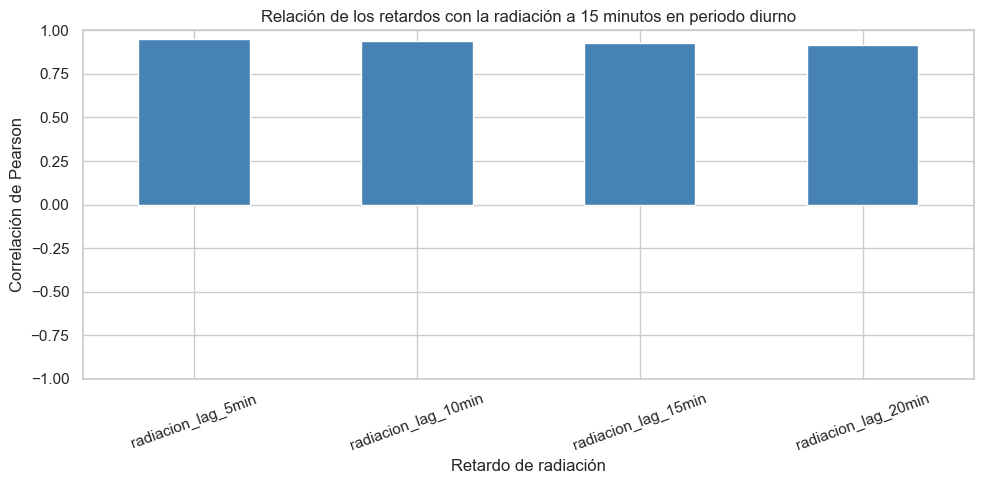

,filas,proporcion_sin_cambio
mismo_origen_t15,,
False,54990,0.462
True,164988,1.000


Porcentaje total sin cambio a 15 minutos: 86.54
Porcentaje diurno sin cambio: 75.11


In [22]:
relaciones_futuras = pd.DataFrame({
    "con_radiacion_actual": base[predictoras + lags].corrwith(base[objetivo]),
    "con_radiacion_t15": base[predictoras + lags].corrwith(base["radiacion_t15"])
})
base_dia = base[base["is_day"] == 1]
relaciones_futuras["con_t15_solo_dia"] = base_dia[predictoras + lags].corrwith(base_dia["radiacion_t15"])
display(relaciones_futuras.round(3))

base_dia[lags + ["radiacion_t15"]].corr()["radiacion_t15"].drop("radiacion_t15").plot.bar(color="steelblue")
plt.title("Relación de los retardos con la radiación a 15 minutos en periodo diurno")
plt.xlabel("Retardo de radiación")
plt.ylabel("Correlación de Pearson")
plt.ylim(-1, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

comparacion = base.dropna(subset=[objetivo, "radiacion_t15"]).copy()
comparacion["sin_cambio"] = comparacion[objetivo] == comparacion["radiacion_t15"]
display(comparacion.groupby("mismo_origen_t15").agg(
    filas=("radiacion_t15", "size"),
    proporcion_sin_cambio=("sin_cambio", "mean")
).round(3))
print("Porcentaje total sin cambio a 15 minutos:", round(comparacion["sin_cambio"].mean() * 100, 2))
print("Porcentaje diurno sin cambio:", round(
    comparacion.loc[comparacion["is_day"] == 1, "sin_cambio"].mean() * 100, 2
))


En aproximadamente **86,54 %** de las parejas, la radiación actual y la de quince minutos
después son iguales. Esto incluye ceros nocturnos y valores repetidos dentro de la misma hora.
Los retardos pueden tener correlaciones muy altas por esta construcción del archivo.

Para evaluar un modelo será necesario compararlo con una referencia sencilla: mantener la
radiación actual como predicción. También habrá que separar resultados diurnos y cambios de
hora de origen. Estos datos no permiten comprobar con detalle la variabilidad solar real
dentro de cada hora. Aquí no entrenamos un modelo ni presentamos métricas predictivas.


## 9. Preparación de una separación temporal
Dejamos planteada la división cronológica 80/20 del anteproyecto. Las dos estaciones comparten
el mismo corte y no repartimos una hora de origen entre entrenamiento y prueba. También
retiramos del entrenamiento las filas cuya etiqueta a 15 minutos llegue al periodo de prueba.


In [23]:
# Elegimos el corte sobre las horas de origen antes de quitar filas por ausentes.
horas_origen = base["radiation_source_timestamp"].dropna().drop_duplicates().sort_values().reset_index(drop=True)
corte = horas_origen.iloc[int(len(horas_origen) * 0.8)]

# Selección provisional: no incluye variables futuras ni las medias horarias del EDA.
entradas = predictoras + [objetivo, "hora"] + lags
base_modelo = base.dropna(subset=entradas + ["radiacion_t15", "tiempo_objetivo"]).copy()

entrenamiento = base_modelo[(base_modelo["radiation_source_timestamp"] < corte) &
                            (base_modelo["tiempo_objetivo"] < corte)].copy()
prueba = base_modelo[base_modelo["radiation_source_timestamp"] >= corte].copy()

print("Corte temporal (UTC):", corte)
print("Filas antes de quitar ausentes:", len(base))
print("Filas con entradas y objetivo completos:", len(base_modelo))
print("Filas de entrenamiento:", len(entrenamiento))
print("Filas de prueba:", len(prueba))
print("Filas retiradas por cruce de la etiqueta con el corte:",
      len(base_modelo) - len(entrenamiento) - len(prueba))
print("Último instante objetivo de entrenamiento:", entrenamiento["tiempo_objetivo"].max())
print("Primer instante de prueba:", prueba["timestamp"].min())


Corte temporal (UTC): 2026-07-03 12:00:00+00:00
Filas antes de quitar ausentes: 219984
Filas con entradas y objetivo completos: 211330
Filas de entrenamiento: 167314
Filas de prueba: 44010
Filas retiradas por cruce de la etiqueta con el corte: 6
Último instante objetivo de entrenamiento: 2026-07-03 11:55:00+00:00
Primer instante de prueba: 2026-07-03 12:00:00+00:00


La proporción final de filas puede diferir de 80/20 por los ausentes y por las filas retiradas
en el límite. Las lecturas anteriores al corte sí pueden servir de historial para los primeros
retardos de prueba, porque ya pertenecen al pasado en el instante de predecir.

La selección de variables es provisional: antes de entrenar hay que resolver la alineación
del UV y comprobar la disponibilidad temporal de todas las fuentes. El EDA usa el periodo
completo para describirlo; la selección definitiva, los ajustes y cualquier imputación del
modelo deberán decidirse usando solo entrenamiento. Las métricas RMSE y R² se calcularán
cuando exista un modelo y un objetivo adecuado, como indica el anteproyecto.


## 10. Conclusiones y relación con el anteproyecto

1. **Disponibilidad y calidad.** Tenemos dos estaciones con una rejilla regular de cinco minutos,
   sin duplicados de estación-fecha. Hay 8.640 filas sin meteorología que no hemos rellenado.
   La preparación responde a RF-01 y conserva la identificación de las estaciones de RF-02.
2. **Resolución real de la radiación.** Los doce registros de cada estación-hora comparten el mismo
   valor solar. No deben interpretarse como doce mediciones independientes. Esto limita lo
   que podremos evaluar a horizontes de 5 a 20 minutos.
3. **Patrones temporales.** La radiación tiene un ciclo diario muy marcado y las medias de las
   estaciones son muy próximas. Las diferencias mensuales describen este periodo, sin demostrar
   una estacionalidad estable a largo plazo.
4. **Relaciones con las variables.** Hemos comparado temperatura, humedad, viento, presión,
   lluvia, visibilidad, UV y nubosidad con la radiación. Separar las horas diurnas cambia las
   correlaciones. Las componentes solares comparten información por su propia definición.
5. **Problema del cruce que debemos revisar.** UV y radiación alcanzan sus máximos medios con unas
   cinco horas de diferencia. Antes de interpretar las relaciones físicas o modelar, necesitamos
   verificar las marcas temporales y la procedencia de ambos conjuntos.
6. **Preparación temporal.** Los retardos de 5, 10, 15 y 20 minutos se construyen por estación,
   con comprobación del intervalo. La etiqueta provisional es radiación a 15 minutos y dejamos
   una división cronológica sin etiquetas de entrenamiento que alcancen el periodo de prueba.
   Esto prepara RF-07 y RF-10, pero no sustituye la evaluación del modelo.
7. **Lo que falta para el objetivo final.** Necesitamos generación o potencia medida con fechas
   compatibles y datos de las instalaciones y del estado de limpieza de los paneles.
   Sin ellos no podemos cuantificar el efecto de la suciedad ni predecir producción eléctrica
   real. Tampoco podemos fijar un umbral de déficit energético usando solo radiación.

El siguiente paso es revisar el cruce temporal y la fuente solar. Una vez resuelto, podremos
incorporar los datos de generación y de paneles y preparar el modelo del anteproyecto.

**Fuentes:** `Solar Aruba Anteproyecto (1).pdf`, apartados 1.2-1.4, RF-01, RF-02, RF-07,
RF-09, RF-10, RF-13 y objetivos del apartado 3; `aruba_cruzado_5min (1).csv`.
